# House Price Prediction – King County, USA

Predicting house sale prices in King County, Washington (the Seattle area) from **21,613 house sales** made between May 2014 and May 2015.

**Steps:** load the data → explore → clean → exploratory analysis → linear regression → polynomial regression pipeline → train/test evaluation (R², RMSE) → Ridge regularization → results summary

## 1. Load the data

In [1]:
import pandas as pd

In [2]:
#importing data from Github
# (if you cloned the repo you can also read the local copy: pd.read_csv("housing.csv"))
git_url = "https://raw.githubusercontent.com/imdsarfraz/Housing-Price-Prediction/main/housing.csv"

In [3]:
df=pd.read_csv(git_url, header=0)

In [4]:
df.head()

,Unnamed: 0,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,0,7129300520,20141013T000000,221900.0,3.0,1.00,1180,5650,1.0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,1,6414100192,20141209T000000,538000.0,3.0,2.25,2570,7242,2.0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,2,5631500400,20150225T000000,180000.0,2.0,1.00,770,10000,1.0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,3,2487200875,20141209T000000,604000.0,4.0,3.00,1960,5000,1.0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,4,1954400510,20150218T000000,510000.0,3.0,2.00,1680,8080,1.0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


## 2. Explore the data

Each row is one house sale. `price` is the target we want to predict; the other columns describe the house (size, rooms, condition, quality grade, location, …).

In [5]:
#Display the data types of each column using the function dtypes.
print(df.dtypes)

Unnamed: 0         int64
id                 int64
date                 str
price            float64
bedrooms         float64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
grade              int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
zipcode            int64
lat              float64
long             float64
sqft_living15      int64
sqft_lot15         int64
dtype: object


In [6]:
# data type for a particular column
print(df['floors'].dtype)

float64


In [7]:
#statistical summary
df.describe()

,Unnamed: 0,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,21613.00000,2.161300e+04,2.161300e+04,21600.000000,21603.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,...,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,10806.00000,4.580302e+09,5.400881e+05,3.372870,2.115736,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,...,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,6239.28002,2.876566e+09,3.671272e+05,0.926657,0.768996,918.440897,4.142051e+04,0.539989,0.086517,0.766318,...,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,0.00000,1.000102e+06,7.500000e+04,1.000000,0.500000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,...,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,5403.00000,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,...,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,10806.00000,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,...,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,16209.00000,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,...,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,21612.00000,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,...,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


In [8]:
# column types and non-null counts → bedrooms and bathrooms have a few missing values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     21613 non-null  int64  
 1   id             21613 non-null  int64  
 2   date           21613 non-null  str    
 3   price          21613 non-null  float64
 4   bedrooms       21600 non-null  float64
 5   bathrooms      21603 non-null  float64
 6   sqft_living    21613 non-null  int64  
 7   sqft_lot       21613 non-null  int64  
 8   floors         21613 non-null  float64
 9   waterfront     21613 non-null  int64  
 10  view           21613 non-null  int64  
 11  condition      21613 non-null  int64  
 12  grade          21613 non-null  int64  
 13  sqft_above     21613 non-null  int64  
 14  sqft_basement  21613 non-null  int64  
 15  yr_built       21613 non-null  int64  
 16  yr_renovated   21613 non-null  int64  
 17  zipcode        21613 non-null  int64  
 18  lat            21

## 3. Clean the data

In [9]:
#Remove Unnecessary Columns
# 'id' is only a sale identifier and 'Unnamed: 0' is a leftover row index from the CSV file,
# so neither tells us anything about the price
# axis=1 → drop along columns
# axis=0 → drop along rows
df=df.drop(["id", "Unnamed: 0"], axis=1)

In [10]:
#Checking Columns having Missing Values
df.isnull().sum().sort_values(ascending=False)

bedrooms         13
bathrooms        10
price             0
date              0
sqft_living       0
sqft_lot          0
floors            0
waterfront        0
view              0
condition         0
grade             0
sqft_above        0
sqft_basement     0
yr_built          0
yr_renovated      0
zipcode           0
lat               0
long              0
sqft_living15     0
sqft_lot15        0
dtype: int64

In [11]:
df.isnull().sum()[df.isnull().sum() > 0]

bedrooms     13
bathrooms    10
dtype: int64

In [12]:
import numpy as np

In [13]:
#replace the missing values with mean
mean_bed = df['bedrooms'].mean()
mean_bath = df['bathrooms'].mean()

# Assign the result back to the column. The chained form
# df['bedrooms'].replace(np.nan, mean_bed, inplace=True) only changes a temporary copy in pandas >= 3.0,
# so the NaNs would silently stay in df and every model below would fail with "Input X contains NaN".
df['bedrooms'] = df['bedrooms'].fillna(mean_bed)
df['bathrooms'] = df['bathrooms'].fillna(mean_bath)

In [14]:
# check again → no missing values left
df.isnull().sum()[df.isnull().sum() > 0]

Series([], dtype: int64)

## 4. Exploratory data analysis

In [15]:
# Count number of houses with each unique floor value
floor_counts = df['floors'].value_counts()
print(floor_counts)

floors
1.0    10680
2.0     8241
1.5     1910
3.0      613
2.5      161
3.5        8
Name: count, dtype: int64


In [16]:
#correlation df.corr()
df[['bedrooms', 'bathrooms', 'price']].corr()

,bedrooms,bathrooms,price
bedrooms,1.000000,0.514194,0.308797
bathrooms,0.514194,1.000000,0.525738
price,0.308797,0.525738,1.000000


<Axes: xlabel='waterfront', ylabel='price'>

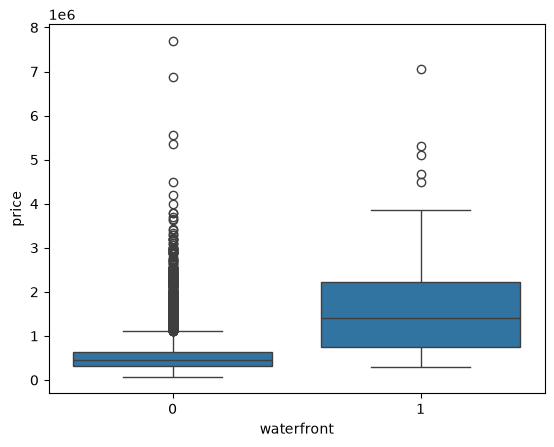

In [17]:
# Box Plot
# Waterfront houses (1) have a much higher median price (≈ $1.4M vs ≈ $450K),
# while houses without a waterfront (0) have far more price outliers
import seaborn as sns
sns.boxplot(x='waterfront', y='price', data=df)

<Axes: xlabel='sqft_living', ylabel='price'>

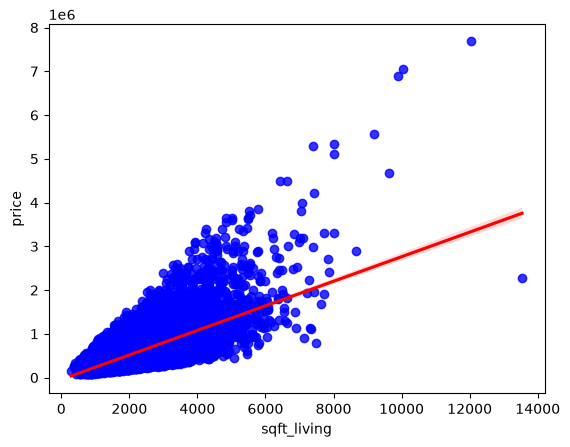

In [18]:
#Regression Plot
# sqft_living is positively correlated with price (r ≈ 0.70); prices spread out more for bigger houses
sns.regplot(x='sqft_living', y='price', data=df, line_kws={'color' : 'red'}, scatter_kws={'color':'blue'})

In [19]:
# 'date' is the only text (non-numeric) column left
df.dtypes

date                 str
price            float64
bedrooms         float64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
grade              int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
zipcode            int64
lat              float64
long             float64
sqft_living15      int64
sqft_lot15         int64
dtype: object

In [20]:
# longitude is almost uncorrelated with price
df[['long','price']].corr()

,long,price
long,1.000000,0.021626
price,0.021626,1.000000


In [21]:
# Correlation can only be computed between numeric columns,
# so keep only the numeric ones (this leaves out the text column 'date')
df_numeric = df.select_dtypes(include=[np.number])
df_numeric.dtypes

price            float64
bedrooms         float64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
grade              int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
zipcode            int64
lat              float64
long             float64
sqft_living15      int64
sqft_lot15         int64
dtype: object

In [22]:
# features most correlated with price: sqft_living, grade, sqft_above, sqft_living15, bathrooms
df_numeric.corr()['price'].sort_values(ascending=False)

price            1.000000
sqft_living      0.702035
grade            0.667434
sqft_above       0.605567
sqft_living15    0.585379
bathrooms        0.525738
view             0.397293
sqft_basement    0.323816
bedrooms         0.308797
lat              0.307003
waterfront       0.266369
floors           0.256794
yr_renovated     0.126434
sqft_lot         0.089661
sqft_lot15       0.082447
yr_built         0.054012
condition        0.036362
long             0.021626
zipcode         -0.053203
Name: price, dtype: float64

## 5. ▶️ Model 1: Linear Regression

`lm.score(X, Y)` returns **R²**: the share of the variation in `price` that the model explains (1 = perfect fit, 0 = no better than always predicting the average price).

In [23]:
from sklearn.linear_model import LinearRegression

In [24]:
#Fit a linear regression model using the longitude feature
X = df[['long']]
Y = df['price']
lm = LinearRegression()
lm.fit(X,Y)
lm.score(X, Y)  # R² ≈ 0 → longitude alone explains almost none of the price variation

0.0004676943014898516

In [25]:
# sqft_living alone explains about 49% of the variation in price
X = df[['sqft_living']]
Y = df['price']
lm = LinearRegression()
lm.fit(X,Y)
lm.score(X, Y) #gives R² on training data only.

0.4928532179037931

In [26]:
# Multiple Linear Regression Model (11 features)
features =["floors", "waterfront","lat" ,"bedrooms" ,"sqft_basement" ,"view" ,"bathrooms","sqft_living15","sqft_above","grade","sqft_living"]
M=df[features]
Y = df['price']
lm = LinearRegression()
lm.fit(M,Y)
lm.score(M, Y)  #gives R² on training data only.

0.6576951666037499

## 6. ▶️ Model 2: Pipeline with Scaling + PolynomialFeatures

This model uses a pipeline with three steps:
1. `StandardScaler()` → scales features (mean = 0, std = 1)
2. `PolynomialFeatures()` → generates higher-order and interaction terms (degree 2 by default)
3. `LinearRegression()` → fits a linear model on these expanded features

Effectively, this becomes a **polynomial regression** model, which can capture non-linear relationships between the features and the target.

🧠 **Summary**
- Model 1 → simple linear, no scaling, less flexible
- Model 2 → polynomial (non-linear), scaled data, more flexible

`include_bias=False` means `PolynomialFeatures` does **not** add a constant column of 1s. The model still has an intercept: `LinearRegression` fits its own (`fit_intercept=True` by default), so that extra column would only be redundant.

⚠️ **Note:** polynomial models can easily overfit if the degree is too high.

In [27]:
from sklearn.metrics import r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler,PolynomialFeatures

In [28]:
#Now better way, Polynomial model
Input=[
    ('scale', StandardScaler()),
    ('polynomial', PolynomialFeatures(include_bias=False)),
    ('model', LinearRegression())]

In [29]:
pipe = Pipeline(Input)
pipe.fit(M,Y)
ypipe = pipe.predict(M)
print(r2_score (Y, ypipe))  # R² on the training data

0.7513408515988733


### 💡 Why polynomial regression often gives a higher R² than linear regression
1. More flexible — can model non-linear curves in the data.
2. Includes interaction terms → captures combined effects of features.
3. Adding polynomial terms increases the number of predictors, and R² on the training data can only improve or stay the same (never decrease).

Higher R² on training data doesn't always mean a better model. Polynomial models can easily overfit — always check R² on test data.

## 7. Always best to split the data between train and test

- If Train R² ≫ Test R², your model overfits (too complex).
- If both are reasonable and close → good predictive performance.

`random_state` locks the randomness:
- Same `random_state` → same train/test split every time (reproducible results).
- No `random_state` → different split on each run.

In [30]:
from sklearn.model_selection import train_test_split

# Model 1 (multiple linear regression, same `features` list as above) on an 80/20 train/test split
X = df[features]
Y = df['price']

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
lm.fit(X_train, Y_train)

print("Train R²:", lm.score(X_train, Y_train))
print("Test R² :", lm.score(X_test, Y_test))

Train R²: 0.6564450189198031
Test R² : 0.6614029431732473


In [31]:
# Model 2 (polynomial pipeline) on the same features and the same split → scores are directly comparable
M = df[features]
Y = df['price']

M_train, M_test, Y_train, Y_test = train_test_split(M, Y, test_size=0.2, random_state=42)

pipe = Pipeline([
    ('scale', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('model', LinearRegression())
])

pipe.fit(M_train, Y_train)

print("Train R²:", pipe.score(M_train, Y_train))
print("Test R² :", pipe.score(M_test, Y_test))

Train R²: 0.7571973911855827
Test R² : 0.7111640481908172


In [32]:
#  Improved prediction accuracy with ~7.6% lower RMSE compared to baseline model.
# lower RMSE better it is (RMSE is in the same unit as price: US dollars)
from sklearn.metrics import mean_squared_error

# X_test and M_test hold the same houses (same features, test_size and random_state),
# so both models are evaluated on exactly the same data

# Model 1
y_pred1 = lm.predict(X_test)
rmse1 = np.sqrt(mean_squared_error(Y_test, y_pred1))
print("Model 1 RMSE:", rmse1)

# Model 2
y_pred2 = pipe.predict(M_test)
rmse2 = np.sqrt(mean_squared_error(Y_test, y_pred2))
print("Model 2 RMSE:", rmse2)

improvement = ((rmse1 - rmse2) / rmse1) * 100
print(f"Improvement in RMSE: {improvement:.2f}%")

Model 1 RMSE: 226247.62944817013
Model 2 RMSE: 208962.36401824164
Improvement in RMSE: 7.64%


## 8. Model Evaluation and Refinement: Ridge Regression

Regularized regression is essential for handling multicollinearity and overfitting.
- Ridge regression adds a penalty (`alpha`) to control large coefficients.
- `alpha = 0` → same as `LinearRegression`
- Higher `alpha` → more regularization (simpler model, less overfitting)
- Useful when features are correlated or the model overfits the training data.

Tip: the penalty acts on the size of the coefficients, which depends on the scale of each feature, so Ridge is usually combined with `StandardScaler` (e.g. in a `Pipeline`). Below it is applied to the raw, unscaled features.

In [33]:
from sklearn.linear_model import Ridge

M_train, M_test, Y_train, Y_test = train_test_split(M, Y, test_size=0.2, random_state=42)

ridge = Ridge(alpha=0.1)   # α = 0.1 means mild regularization
ridge.fit(M_train, Y_train)

print("Train R²:", ridge.score(M_train, Y_train))
print("Test R² :", ridge.score(M_test, Y_test))

Train R²: 0.6564449978833939
Test R² : 0.661398298309094


In [34]:
# COMPARISON
lm = LinearRegression().fit(M_train, Y_train)
ridge = Ridge(alpha=0.1).fit(M_train, Y_train)

print("Linear Regression R² (Train):", lm.score(M_train, Y_train))
print("Ridge Regression R² (Train):", ridge.score(M_train, Y_train))


print("Linear Regression R² (Test) :", lm.score(M_test, Y_test))
print("Ridge Regression R² (Test) :", ridge.score(M_test, Y_test))

Linear Regression R² (Train): 0.6564450189198031
Ridge Regression R² (Train): 0.6564449978833939
Linear Regression R² (Test) : 0.6614029431732473
Ridge Regression R² (Test) : 0.661398298309094


**Result:** Linear and Ridge regression give practically the same scores (they differ only in the 6th decimal place, and Linear is even marginally higher on the test set). Why?

- **No overfitting:** Train R² (≈ 0.656) and Test R² (≈ 0.661) are almost equal, so there is nothing for regularization to fix.
- **α = 0.1 is a very weak penalty** for ~17,000 training rows, so the coefficients barely change (the plot below shows R² only starts to drop once α goes above ≈ 10).
- **Multicollinearity *is* present:** `sqft_living = sqft_above + sqft_basement` for every house (checked in the next cell), and `sqft_living` is also strongly correlated with `grade`, `sqft_living15` and `bathrooms` (r ≈ 0.76). This makes the individual coefficients unstable and hard to interpret, but it doesn't hurt the predictions, so R² is unaffected.

The textbook pattern — *Linear Regression: higher Train R² but lower Test R² (overfitting); Ridge Regression: slightly lower Train R² but higher Test R² (better generalization)* — only appears when the unregularized model overfits, e.g. with many features, high-degree polynomial terms or little data.

In [35]:
# sqft_living is exactly sqft_above + sqft_basement for every house → perfect multicollinearity
print((df['sqft_living'] == df['sqft_above'] + df['sqft_basement']).all())

True


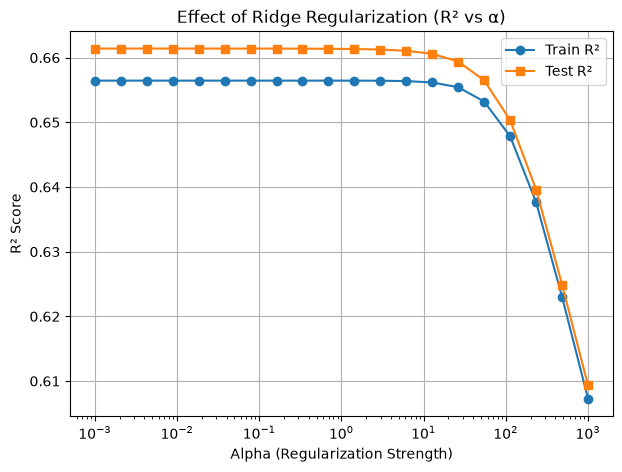

In [36]:
# GRAPHICALLY
# (R² vs α)
# The test score is used here only to illustrate the effect of α. To actually pick α,
# use cross-validation on the training data (e.g. RidgeCV) so the test set stays unseen.
import matplotlib.pyplot as plt

alphas = np.logspace(-3, 3, 20)  # alpha values from 0.001 to 1000
train_scores = []
test_scores = []

for a in alphas:
    ridge = Ridge(alpha=a)
    ridge.fit(M_train, Y_train)
    train_scores.append(ridge.score(M_train, Y_train))
    test_scores.append(ridge.score(M_test, Y_test))

plt.figure(figsize=(7, 5))
plt.plot(alphas, train_scores, label="Train R²", marker='o')
plt.plot(alphas, test_scores, label="Test R²", marker='s')
plt.xscale('log')
plt.xlabel("Alpha (Regularization Strength)")
plt.ylabel("R² Score")
plt.title("Effect of Ridge Regularization (R² vs α)")
plt.legend()
plt.grid(True)
plt.show()

In [37]:
# Ridge (α = 0.1) again, but on a different split: 85% train / 15% test.
# The Test R² differs from the 80/20 result above mainly because different houses end up in the test set →
# a single split gives a noisy estimate; cross-validation (cross_val_score) averages over several splits.
X = df[features]
Y = df['price']

x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.15, random_state=42)

ridge = Ridge(alpha=0.1)
ridge.fit(x_train, y_train)
yhat = ridge.predict(x_test)

# r2_score(y_test, yhat) gives the same value as ridge.score(x_test, y_test);
# computing yhat yourself is handy when you also need the predictions (e.g. for RMSE or plots)
print("Train R²:", ridge.score(x_train, y_train))
print("Test R² :", r2_score(y_test, yhat))

Train R²: 0.6598169790864628
Test R² : 0.6464959934334678


## 9. Results summary

All three models use the same 11 features and the same 80/20 train/test split (`random_state=42`):

| Model | Train R² | Test R² | Test RMSE (USD) |
|---|:---:|:---:|:---:|
| Model 1 – Multiple linear regression | 0.656 | 0.661 | 226,248 |
| **Model 2 – Polynomial regression pipeline (degree 2)** | 0.757 | **0.711** | **208,962** |
| Ridge regression (α = 0.1) | 0.656 | 0.661 | – |

- **Best model:** the polynomial pipeline explains ~71% of the price variation on unseen houses and has a ~7.6% lower RMSE than plain linear regression.
- Its gap between Train R² and Test R² (0.757 vs 0.711) shows some overfitting.
- Ridge doesn't change the linear model's scores, because that model isn't overfitting in the first place.
- The strongest single predictors of price are `sqft_living` (r = 0.70), `grade` (0.67) and `sqft_above` (0.61).